<a href="https://colab.research.google.com/github/iXalbert/AI-Powered-Sports-Video-Analysis-and-Tactical-Intelligence-Platform/blob/main/notebooks/01_player_tracking_and_stats.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q ultralytics opencv-python matplotlib supervision lap

In [5]:
import os
import cv2
import json
import torch
import numpy as np
import supervision as sv
import matplotlib.pyplot as plt
from ultralytics import YOLO

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device name: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu130
CUDA available: True
Device name: Tesla T4


In [7]:
INPUT_VIDEO_PATH = "meci_test.mp4"  # Schimbă numele dacă fișierul tău are altă denumire

if not os.path.exists(INPUT_VIDEO_PATH):
    raise FileNotFoundError(
        f"❌ Fișierul '{INPUT_VIDEO_PATH}' nu există! "
        f"Încarcă videoclipul din laptop în panoul din stânga (Files)."
    )

video_info = sv.VideoInfo.from_video_path(INPUT_VIDEO_PATH)
print("✅ Videoclip încărcat cu succes!")
print(f"Rezoluție: {video_info.width}x{video_info.height}")
print(f"FPS: {video_info.fps}")
print(f"Cadre totale în fișier: {video_info.total_frames}")

# Limităm procesarea la maximum 5 minute (300 secunde)
MAX_MINUTES = 5
MAX_FRAMES = int(min(video_info.total_frames, video_info.fps * 60 * MAX_MINUTES))
print(f"⏱️ Se vor procesa maximum {MAX_FRAMES} cadre (~{MAX_MINUTES} minute).")

✅ Videoclip încărcat cu succes!
Rezoluție: 1920x1080
FPS: 60.0
Cadre totale în fișier: 864
⏱️ Se vor procesa maximum 864 cadre (~5 minute).


In [12]:
model = YOLO('yolov8n.pt')

# Folosim BoxAnnotator și LabelAnnotator din supervision pentru vizualizare
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

PERSON_CLASS_ID = 0
OUTPUT_VIDEO_PATH = "output_tracking.mp4"
METADATA_JSON_PATH = "tracking_stats.json"

tracking_data = []
zone_counts = {"left": 0, "center": 0, "right": 0}

def process_frame(frame: cv2.Mat, frame_idx: int) -> cv2.Mat:
    if frame_idx >= MAX_FRAMES:
        return frame

    # 1. Rulăm detecția + tracking-ul ByteTrack direct prin YOLOv8 nativ
    results = model.track(frame, persist=True, tracker="bytetrack.yaml", verbose=False)[0]

    # 2. Convertim rezultatele în format Supervision pentru vizualizare ușoară
    detections = sv.Detections.from_ultralytics(results)

    # 3. Filtrăm doar persoanele/jucătorii (clasa 0)
    detections = detections[detections.class_id == PERSON_CLASS_ID]

    frame_record = {
        "frame_index": frame_idx,
        "timestamp_sec": round(frame_idx / video_info.fps, 2),
        "players": []
    }

    frame_x_positions = []

    # Verificăm dacă avem ID-uri de tracking atribuite
    if detections.tracker_id is not None:
        for xyxy, tracker_id in zip(detections.xyxy, detections.tracker_id):
            center_x = (xyxy[0] + xyxy[2]) / 2
            bottom_y = xyxy[3]

            frame_x_positions.append(center_x)

            frame_record["players"].append({
                "track_id": int(tracker_id),
                "bbox": [round(float(c), 2) for c in xyxy],
                "position": [round(float(center_x), 2), round(float(bottom_y), 2)]
            })

    tracking_data.append(frame_record)

    # 4. Calculare distribuție zonă de atac (Flashscore style)
    if frame_x_positions:
        avg_x = sum(frame_x_positions) / len(frame_x_positions)
        width_third = video_info.width / 3

        if avg_x < width_third:
            zone_counts["left"] += 1
        elif avg_x < 2 * width_third:
            zone_counts["center"] += 1
        else:
            zone_counts["right"] += 1

    # 5. Anotare vizuală pe cadru
    labels = [f"#{tid}" for tid in detections.tracker_id] if detections.tracker_id is not None else []
    annotated_frame = box_annotator.annotate(scene=frame.copy(), detections=detections)
    annotated_frame = label_annotator.annotate(scene=annotated_frame, detections=detections, labels=labels)

    return annotated_frame

print("Se procesează videoclipul cu YOLOv8 + ByteTrack nativ...")
sv.process_video(
    source_path=INPUT_VIDEO_PATH,
    target_path=OUTPUT_VIDEO_PATH,
    callback=process_frame
)

# Salvare metadate structurate JSON
with open(METADATA_JSON_PATH, "w") as f:
    json.dump({
        "video_info": {"width": video_info.width, "height": video_info.height, "fps": video_info.fps},
        "zone_distribution": zone_counts,
        "frames": tracking_data
    }, f, indent=2)

print(f"✅ Procesare completă fără erori!")
print(f"Video salvat: {OUTPUT_VIDEO_PATH}")
print(f"Metadate salvate: {METADATA_JSON_PATH}")

Se procesează videoclipul cu YOLOv8 + ByteTrack nativ...
✅ Procesare completă fără erori!
Video salvat: output_tracking.mp4
Metadate salvate: tracking_stats.json



📊 === FLASHSCORE STYLE MATCH STATS ===
Attacking Side Distribution:
  • Left Flank:   3.2%
  • Central Zone: 81.3%
  • Right Flank:  15.5%



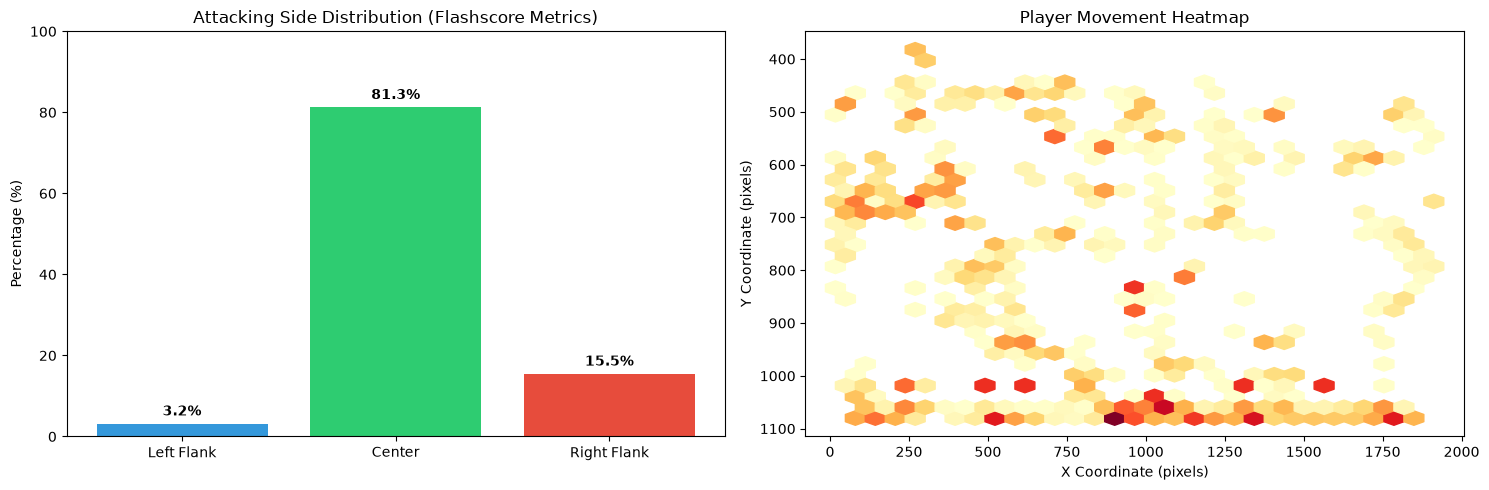

✅ Dashboard salvat ca 'match_summary_dashboard.png'!


In [10]:
# 1. Calcul procente zone de atac
total_analyzed_frames = sum(zone_counts.values()) or 1
left_pct = round((zone_counts["left"] / total_analyzed_frames) * 100, 1)
center_pct = round((zone_counts["center"] / total_analyzed_frames) * 100, 1)
right_pct = round((zone_counts["right"] / total_analyzed_frames) * 100, 1)

print("\n📊 === FLASHSCORE STYLE MATCH STATS ===")
print(f"Attacking Side Distribution:")
print(f"  • Left Flank:   {left_pct}%")
print(f"  • Central Zone: {center_pct}%")
print(f"  • Right Flank:  {right_pct}%")
print("=======================================\n")

# 2. Vizualizare Grafică: Heatmap + Bar chart pentru zone
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Grafic Bar Chart - Zone de Atac
zones = ['Left Flank', 'Center', 'Right Flank']
percentages = [left_pct, center_pct, right_pct]
colors = ['#3498db', '#2ecc71', '#e74c3c']

ax1.bar(zones, percentages, color=colors)
ax1.set_ylabel('Percentage (%)')
ax1.set_title('Attacking Side Distribution (Flashscore Metrics)')
ax1.set_ylim(0, 100)
for i, v in enumerate(percentages):
    ax1.text(i, v + 2, f"{v}%", ha='center', fontweight='bold')

# Grafic Heatmap - Pozitii Jucatori
all_x, all_y = [], []
for f in tracking_data:
    for p in f["players"]:
        all_x.append(p["position"][0])
        all_y.append(p["position"][1])

ax2.hexbin(all_x, all_y, gridsize=30, cmap='YlOrRd', mincnt=1)
ax2.invert_yaxis()
ax2.set_title('Player Movement Heatmap')
ax2.set_xlabel('X Coordinate (pixels)')
ax2.set_ylabel('Y Coordinate (pixels)')

plt.tight_layout()
plt.savefig("match_summary_dashboard.png")
plt.show()

print("✅ Dashboard salvat ca 'match_summary_dashboard.png'!")